# Taller 05 (extensión): Mapa de calor, pares de variables y claridad de las fronteras

Partimos del notebook `05_Comparacion_Clasificadores` (dataset **Wine** de scikit-learn) y hacemos tres cosas:

1. Un **mapa de calor de correlaciones** para encontrar la tercera característica más representativa.
2. Gráficos de **pares** de esa característica contra `Alcohol` y `Flavonoides`.
3. Evaluar **k-NN, Árbol de Decisión y Naive Bayes** sobre esos pares para ver cuál deja la clasificación más clara en un gráfico.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
warnings.filterwarnings('ignore')

from scipy import ndimage
from matplotlib.colors import ListedColormap
from sklearn.datasets import load_wine
from sklearn.model_selection import train_test_split, cross_val_score, StratifiedKFold
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.naive_bayes import GaussianNB
from sklearn.inspection import DecisionBoundaryDisplay

datos_vino = load_wine()
X = pd.DataFrame(datos_vino.data, columns=datos_vino.feature_names)
y = pd.Series(datos_vino.target, name="Clase_de_Vino")

# Mismo mapeo al español que usa el notebook original
X = X.rename(columns={
    'alcohol': 'Alcohol', 'malic_acid': 'Acido_Malico', 'ash': 'Ceniza',
    'alcalinity_of_ash': 'Alcalinidad_Ceniza', 'magnesium': 'Magnesio',
    'total_phenols': 'Fenoles_Totales', 'flavanoids': 'Flavonoides',
    'nonflavanoid_phenols': 'Fenoles_No_Flavonoides',
    'proanthocyanins': 'Proantocianidinas', 'color_intensity': 'Intensidad_Color',
    'hue': 'Matiz', 'od280/od315_of_diluted_wines': 'OD280_OD315', 'proline': 'Prolina'})
print(X.shape, "| clases:", y.value_counts().sort_index().to_dict())

(178, 13) | clases: {0: 59, 1: 71, 2: 48}


## 1. Mapa de calor de correlaciones

Agrego la clase como una columna más para que el mapa muestre también cuánto se relaciona cada variable química con el cultivo.

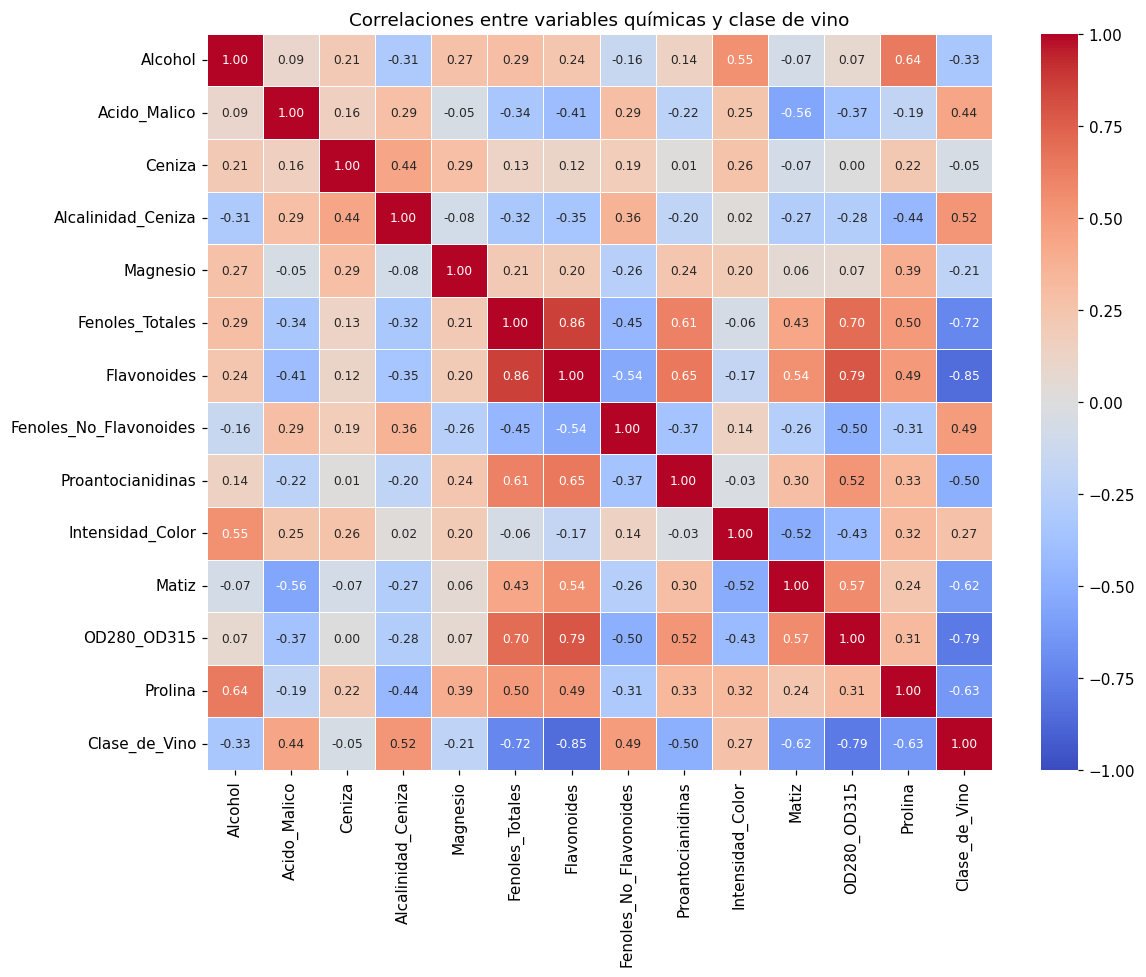

In [2]:
df = X.copy()
df['Clase_de_Vino'] = y

corr = df.corr()

plt.figure(figsize=(11, 9))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="coolwarm", center=0,
            vmin=-1, vmax=1, linewidths=0.5, annot_kws={"size": 8})
plt.title("Correlaciones entre variables químicas y clase de vino")
plt.tight_layout()
plt.show()

### ¿Cuál es la tercera característica más representativa?

Uso como criterio la fila `Clase_de_Vino` del mapa: cuanto mayor es el valor absoluto de la correlación, más se mueve la variable junto con el cultivo. Ordeno de mayor a menor.

In [3]:
ranking = corr['Clase_de_Vino'].drop('Clase_de_Vino').abs().sort_values(ascending=False)
print(ranking.round(3).to_string())

tercera = ranking.index[2]
print(f"\n1.ª: {ranking.index[0]} | 2.ª: {ranking.index[1]} | 3.ª: {tercera}")
print(f"\n{tercera} vs Flavonoides: r = {corr.loc[tercera, 'Flavonoides']:.2f}")
print(f"{tercera} vs Alcohol:     r = {corr.loc[tercera, 'Alcohol']:.2f}")

Flavonoides               0.847
OD280_OD315               0.788
Fenoles_Totales           0.719
Prolina                   0.634
Matiz                     0.617
Alcalinidad_Ceniza        0.518
Proantocianidinas         0.499
Fenoles_No_Flavonoides    0.489
Acido_Malico              0.438
Alcohol                   0.328
Intensidad_Color          0.266
Magnesio                  0.209
Ceniza                    0.050

1.ª: Flavonoides | 2.ª: OD280_OD315 | 3.ª: Fenoles_Totales

Fenoles_Totales vs Flavonoides: r = 0.86
Fenoles_Totales vs Alcohol:     r = 0.29


**Resultado.** Por correlación con la clase, el podio es `Flavonoides`, `OD280_OD315` y **`Fenoles_Totales`** (la tercera). Dos cosas que conviene tener presentes:

- `Alcohol` aparece bastante más abajo en el ranking. Es una variable que ayuda, pero no es de las que más separan los cultivos.
- `Fenoles_Totales` está muy correlacionada con `Flavonoides` (r alrededor de 0.86), así que gran parte de su información se repite. Eso lo veremos en los gráficos de pares.

Una nota metodológica: la clase es una etiqueta (0, 1, 2) y no una cantidad, de modo que la correlación de Pearson con ella es solo una guía rápida. Más abajo la contrasto con otra medida (ANOVA).

In [4]:
from sklearn.feature_selection import f_classif
F, _ = f_classif(X, y)
anova = pd.Series(F, index=X.columns).sort_values(ascending=False)
comparacion = pd.DataFrame({
    'Rank |r| con clase': ranking.rank(ascending=False).astype(int),
    'Rank F-ANOVA': anova.rank(ascending=False).astype(int)
}).sort_values('Rank |r| con clase')
print(comparacion.head(6).to_string())

                    Rank |r| con clase  Rank F-ANOVA
Flavonoides                          1             1
OD280_OD315                          2             3
Fenoles_Totales                      3             7
Prolina                              4             2
Matiz                                5             6
Alcalinidad_Ceniza                   6             9


Aquí hay que ser honestos: **la elección no es robusta al método**. Con ANOVA, `Flavonoides` sigue primera, pero `Prolina` sube al 2.º puesto y `Fenoles_Totales` cae al 7.º, porque su información se solapa con la de `Flavonoides`. Como el enunciado pide el mapa de calor de correlaciones, me quedo con `Fenoles_Totales` (3.ª por |r|). Si se buscara la variable que más *aporta* aparte de `Flavonoides`, `Prolina` u `OD280_OD315` serían mejores candidatas.

## 2. Gráficos de pares: la tercera característica contra Alcohol y Flavonoides

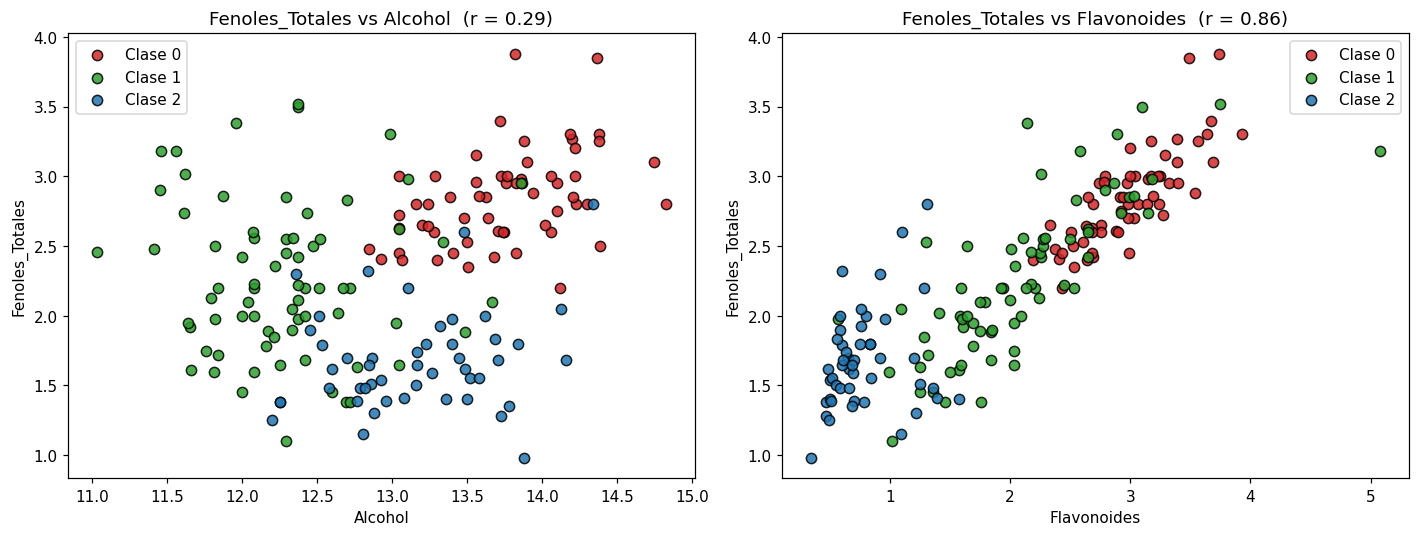

In [5]:
tercera = 'Fenoles_Totales'
nombres_clase = [f"Clase {i}" for i in range(3)]
colores = ['#d62728', '#2ca02c', '#1f77b4']

fig, axes = plt.subplots(1, 2, figsize=(13, 5))
for ax, otra in zip(axes, ['Alcohol', 'Flavonoides']):
    for c in range(3):
        m = y == c
        ax.scatter(X.loc[m, otra], X.loc[m, tercera], c=colores[c],
                   edgecolor='k', s=45, alpha=0.85, label=nombres_clase[c])
    r = X[otra].corr(X[tercera])
    ax.set_xlabel(otra); ax.set_ylabel(tercera)
    ax.set_title(f"{tercera} vs {otra}  (r = {r:.2f})")
    ax.legend()
plt.tight_layout()
plt.show()

Lo que se ve:

- **Fenoles_Totales vs Flavonoides:** los puntos forman casi una diagonal. La Clase 0 arriba a la derecha, la Clase 2 abajo a la izquierda y la Clase 1 en medio, con algo de mezcla. Se separa bien en una dirección, pero la segunda variable aporta poco que la primera no diga ya.
- **Fenoles_Totales vs Alcohol:** aquí la nube es más ancha. `Alcohol` ayuda a distinguir la Clase 1 (graduación más baja) de la Clase 0, y `Fenoles_Totales` ayuda a apartar la Clase 2. Las dos variables se complementan más que en el otro par.

## 3. Evaluación de los tres modelos sobre cada par

Para cada par entreno los tres clasificadores usando solo esas dos columnas. Los tres van dentro de un `Pipeline` con `StandardScaler`, de modo que el trato sea igual para todos y el gráfico pueda dibujarse en las unidades reales de cada eje.

Para medir la "claridad" no me quedo solo con el ojo. Uso tres números:

- **Accuracy en test** (30 %, `random_state=42`, igual que el notebook original) y **accuracy con validación cruzada de 5 pliegues**, porque 54 botellas de test son pocas.
- **Brecha train - test**: si es grande, la frontera está memorizando ruido.
- **Regiones en el mapa**: cuento los parches conectados de color en la cuadrícula de predicción. Con 3 clases lo ideal son 3. Muchos parches significan islas sueltas y una frontera difícil de leer.

In [6]:
modelos = {
    'k-NN (k=5)':        lambda: make_pipeline(StandardScaler(), KNeighborsClassifier(n_neighbors=5)),
    'Árbol (depth=4)':   lambda: make_pipeline(StandardScaler(), DecisionTreeClassifier(max_depth=4, random_state=42)),
    'Naive Bayes':       lambda: make_pipeline(StandardScaler(), GaussianNB()),
}
pares = [('Alcohol', tercera), ('Flavonoides', tercera)]
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

def contar_regiones(modelo, cols, n=300):
    x0, x1 = X[cols[0]].agg(['min', 'max']); y0, y1 = X[cols[1]].agg(['min', 'max'])
    gx, gy = np.meshgrid(np.linspace(x0, x1, n), np.linspace(y0, y1, n))
    malla = pd.DataFrame({cols[0]: gx.ravel(), cols[1]: gy.ravel()})
    z = modelo.predict(malla).reshape(gx.shape)
    return sum(ndimage.label(z == c)[1] for c in np.unique(z))

filas, ajustados = [], {}
for par in pares:
    cols = list(par)
    Xtr, Xte, ytr, yte = train_test_split(X[cols], y, test_size=0.30, random_state=42, stratify=y)
    for nombre, fabrica in modelos.items():
        m = fabrica().fit(Xtr, ytr)
        ajustados[(par, nombre)] = m
        filas.append({
            'Par': f"{par[0]} + {par[1]}", 'Modelo': nombre,
            'Acc train': m.score(Xtr, ytr), 'Acc test': m.score(Xte, yte),
            'Acc CV (5)': cross_val_score(fabrica(), X[cols], y, cv=cv).mean(),
            'Regiones': contar_regiones(m, cols),
        })

res = pd.DataFrame(filas)
res['Brecha'] = res['Acc train'] - res['Acc test']
print(res.round(3).to_string(index=False))

                          Par          Modelo  Acc train  Acc test  Acc CV (5)  Regiones  Brecha
    Alcohol + Fenoles_Totales      k-NN (k=5)      0.879     0.815       0.843         5   0.064
    Alcohol + Fenoles_Totales Árbol (depth=4)      0.944     0.778       0.820         6   0.166
    Alcohol + Fenoles_Totales     Naive Bayes      0.871     0.778       0.848         3   0.093
Flavonoides + Fenoles_Totales      k-NN (k=5)      0.798     0.778       0.776        15   0.021
Flavonoides + Fenoles_Totales Árbol (depth=4)      0.855     0.796       0.753         5   0.059
Flavonoides + Fenoles_Totales     Naive Bayes      0.758     0.889       0.769         3  -0.131


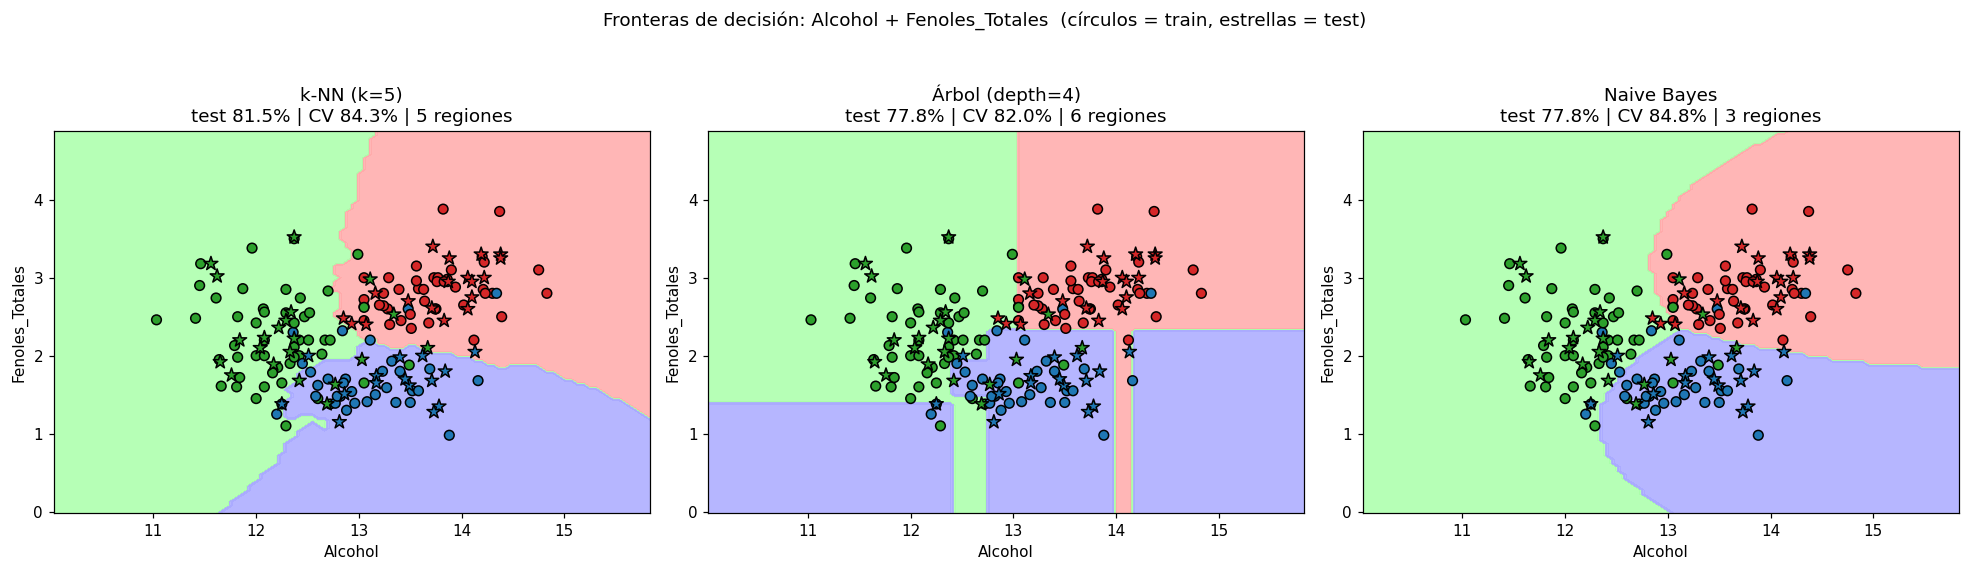

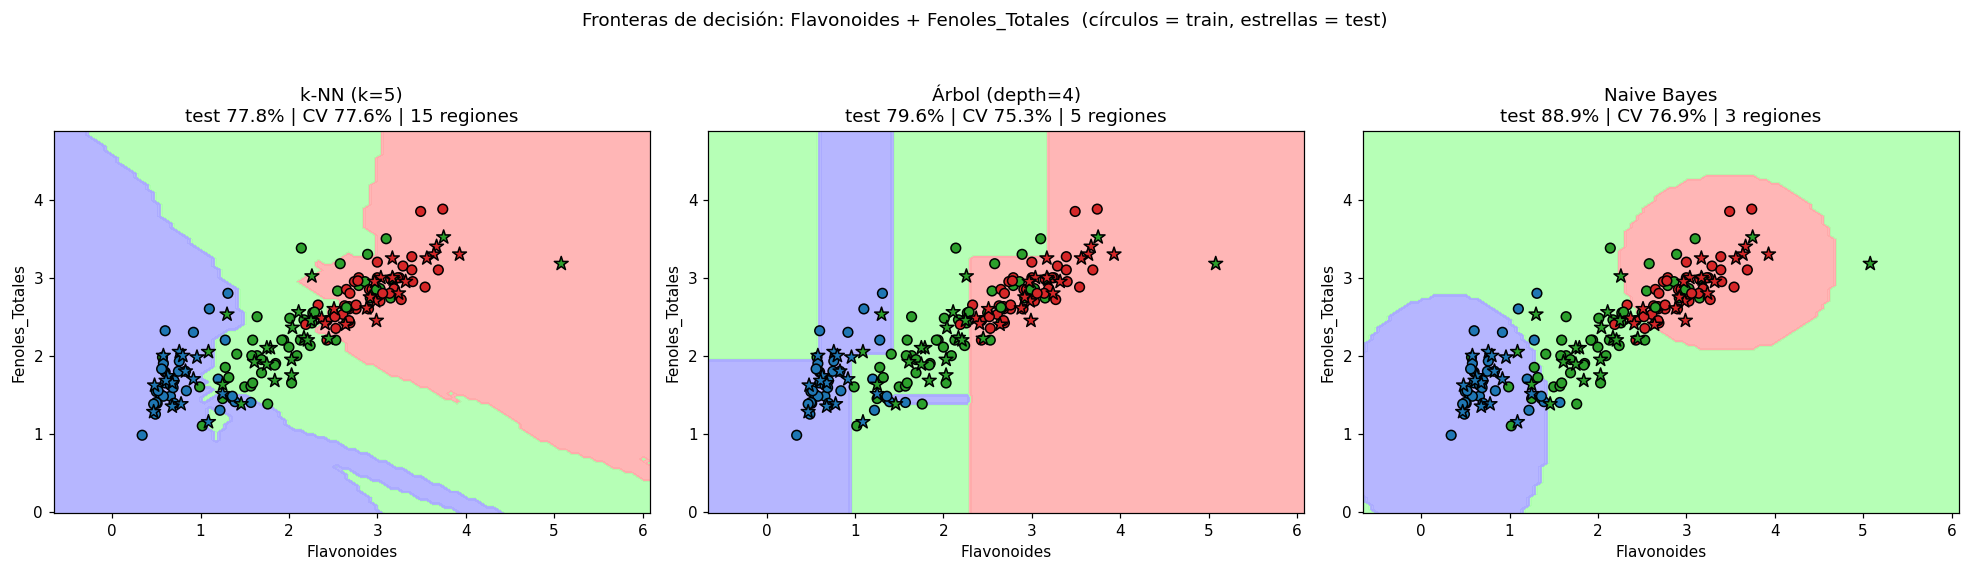

In [7]:
cmap_fondo = ListedColormap(['#FFAAAA', '#AAFFAA', '#AAAAFF'])
cmap_punto = ListedColormap(colores)

for par in pares:
    cols = list(par)
    Xtr, Xte, ytr, yte = train_test_split(X[cols], y, test_size=0.30, random_state=42, stratify=y)
    fig, axes = plt.subplots(1, 3, figsize=(18, 5))
    for ax, nombre in zip(axes, modelos):
        m = ajustados[(par, nombre)]
        DecisionBoundaryDisplay.from_estimator(m, X[cols], cmap=cmap_fondo, ax=ax, alpha=0.85,
                                               response_method='predict')
        ax.scatter(Xtr[cols[0]], Xtr[cols[1]], c=ytr, cmap=cmap_punto, edgecolor='k', s=40)
        ax.scatter(Xte[cols[0]], Xte[cols[1]], c=yte, cmap=cmap_punto, edgecolor='k', s=90, marker='*')
        fila = res[(res['Par'] == f"{par[0]} + {par[1]}") & (res['Modelo'] == nombre)].iloc[0]
        ax.set_title(f"{nombre}\ntest {fila['Acc test']*100:.1f}% | CV {fila['Acc CV (5)']*100:.1f}% | {int(fila['Regiones'])} regiones")
        ax.set_xlabel(cols[0]); ax.set_ylabel(cols[1])
    fig.suptitle(f"Fronteras de decisión: {par[0]} + {par[1]}  (círculos = train, estrellas = test)", y=1.03)
    plt.tight_layout()
    plt.show()

## 4. Conclusión

In [8]:
resumen = (res.groupby('Modelo')[['Acc test', 'Acc CV (5)', 'Brecha', 'Regiones']]
              .mean().sort_values('Acc CV (5)', ascending=False))
print(resumen.round(3).to_string())

                 Acc test  Acc CV (5)  Brecha  Regiones
Modelo                                                 
k-NN (k=5)          0.796       0.809   0.042      10.0
Naive Bayes         0.833       0.809  -0.019       3.0
Árbol (depth=4)     0.787       0.787   0.112       5.5


**Qué dicen los números y los gráficos**

- **Naive Bayes** es el que mejor se lee. Con ambos pares dibuja exactamente **3 regiones**, una por clase, con bordes suaves y sin islas. Promedia el mejor accuracy en test (83 %) y empata con k-NN en validación cruzada (81 %). Su brecha train - test es casi cero. Se entiende que haga esto: dos variables continuas por clase con forma más o menos de campana es justo lo que su modelo asume.
- **k-NN** acierta parecido, pero su mapa es el más ruidoso. Con `Flavonoides + Fenoles_Totales` fragmenta el plano en **15 regiones** porque las clases 0, 1 y 2 se pegan en una diagonal estrecha y los vecinos votan distinto de un punto a otro. Hay franjas azules y verdes que cruzan zonas donde no hay datos.
- **Árbol de Decisión** es fácil de explicar (cortes rectos, reglas "mayor que / menor que"), pero es el que más memoriza: brecha train - test de 11 puntos de media y rectángulos pequeños que rodean puntos sueltos, por ejemplo las tiras verde y azul en `Alcohol + Fenoles_Totales`.

**Veredicto:** para la *representación gráfica* más clara gana **Naive Bayes**. Si lo que importa es explicar la decisión con reglas, el árbol sigue siendo la opción, pero su gráfico es peor.

**Salvedades que no quiero esconder**

- Con solo 2 variables, ningún modelo pasa del ~85 % en validación cruzada. Con las 13 variables, k-NN y Naive Bayes llegan a ~97 % en validación cruzada y el árbol a ~88 %, así que estos mapas sirven para *entender* a los algoritmos, no para decidir cuál usar en producción.
- El 88.9 % de Naive Bayes en test con `Flavonoides + Fenoles_Totales` es optimista. Su CV es 76.9 %, y 54 botellas de test dan resultados muy volátiles. Pesa más la columna de validación cruzada.
- En ese mismo par, el borde de Naive Bayes es un óvalo cómodo de leer, pero deja casi toda la zona intermedia como Clase 1, aunque `Fenoles_Totales` y `Flavonoides` son tan colineales (r = 0.86) que casi no aportan información nueva una a la otra. El par `Alcohol + Fenoles_Totales` es el más informativo de los dos.